# Day 085 | Ground Motion Prediction with LSTM

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning — Capstone | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Ground motion dataset EDA | Distributions and correlations | Magnitude vs PGA scatter |
| Log-transform of targets | Handle lognormal ground motion | PGA spans 0.01 – 1.5 g (3 orders) |
| Feature engineering | Encode categorical site/fault | site_class → ordinal |
| LSTM for tabular regression | Treat features as a "sequence" | Multi-output PGA/PGV/Sa |
| Feedforward NN baseline | Vanilla MLP comparison | Same dataset, same training |
| R² and RMSE per output | Multi-output evaluation | PGA, PGV, Sa(0.2s), Sa(1.0s) |
| LSTM vs FFN vs XGBoost | Three-way comparison | Which approach wins? |
| Phase 4 summary | Review all 25 days of DL | What you can do now |

---

## Our Geotechnical Problem

**Ground Motion Prediction Equations (GMPEs)** are the backbone of seismic hazard analysis.
Given earthquake source parameters and site conditions, predict peak ground motion metrics
used in seismic design:

```
  Input:
  ──────────────────────────
  Magnitude   (5 – 8 Mw)
  Distance    (5 – 200 km)
  Depth       (5 – 30 km)
  Vs30        (150 – 800 m/s)       Output:
  Site class  (A / B / C / D / E)  ─────────────────────────
  Fault type  (SS / Rev / Normal)  PGA  (g)
                                   PGV  (cm/s)
                                   Sa(0.2s) (g)
                                   Sa(1.0s) (g)
```

> This is the **Phase 4 Capstone** — combining everything learned in Days 061–085.

## Part 1: Load and Explore the Ground Motion Dataset

In [1]:
# ───────────────────────────────────────────────────────
# IMPORTS
# ───────────────────────────────────────────────────────

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

torch.manual_seed(42)
np.random.seed(42)

print("Libraries loaded.")
print(f"PyTorch: {torch.__version__}")

Libraries loaded.
PyTorch: 2.5.1


In [2]:
# ───────────────────────────────────────────────────────
# LOAD DATASET
# ───────────────────────────────────────────────────────

df = pd.read_csv('ground_motion_data.csv')

print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
print(df.head())
print("\nDescriptive statistics:")
print(df.describe().round(3))

Shape: (200, 11)

First 5 rows:
  earthquake_id  magnitude  distance_km  depth_km   Vs30 site_class  \
0        EQ0001       6.12        130.2       7.6  260.0          C   
1        EQ0002       7.85         21.4      27.6  331.0          C   
2        EQ0003       7.20         36.5      17.6  265.0          C   
3        EQ0004       6.80        180.2      25.7  208.0          C   
4        EQ0005       5.47        123.3      13.0  228.0          C   

    fault_type   PGA_g  PGV_cms  Sa_02s  Sa_10s  
0       normal  0.0100     1.12  0.0341  0.0100  
1      reverse  1.5000   103.70  3.0000  0.9204  
2  strike-slip  0.0927    13.62  0.2948  0.0794  
3       normal  0.0100     1.00  0.0213  0.0112  
4      reverse  0.0100     1.30  0.0245  0.0110  

Descriptive statistics:
       magnitude  distance_km  depth_km     Vs30    PGA_g  PGV_cms   Sa_02s  \
count    200.000      200.000   200.000  200.000  200.000  200.000  200.000   
mean       6.452      103.352    18.016  461.245    0.096 

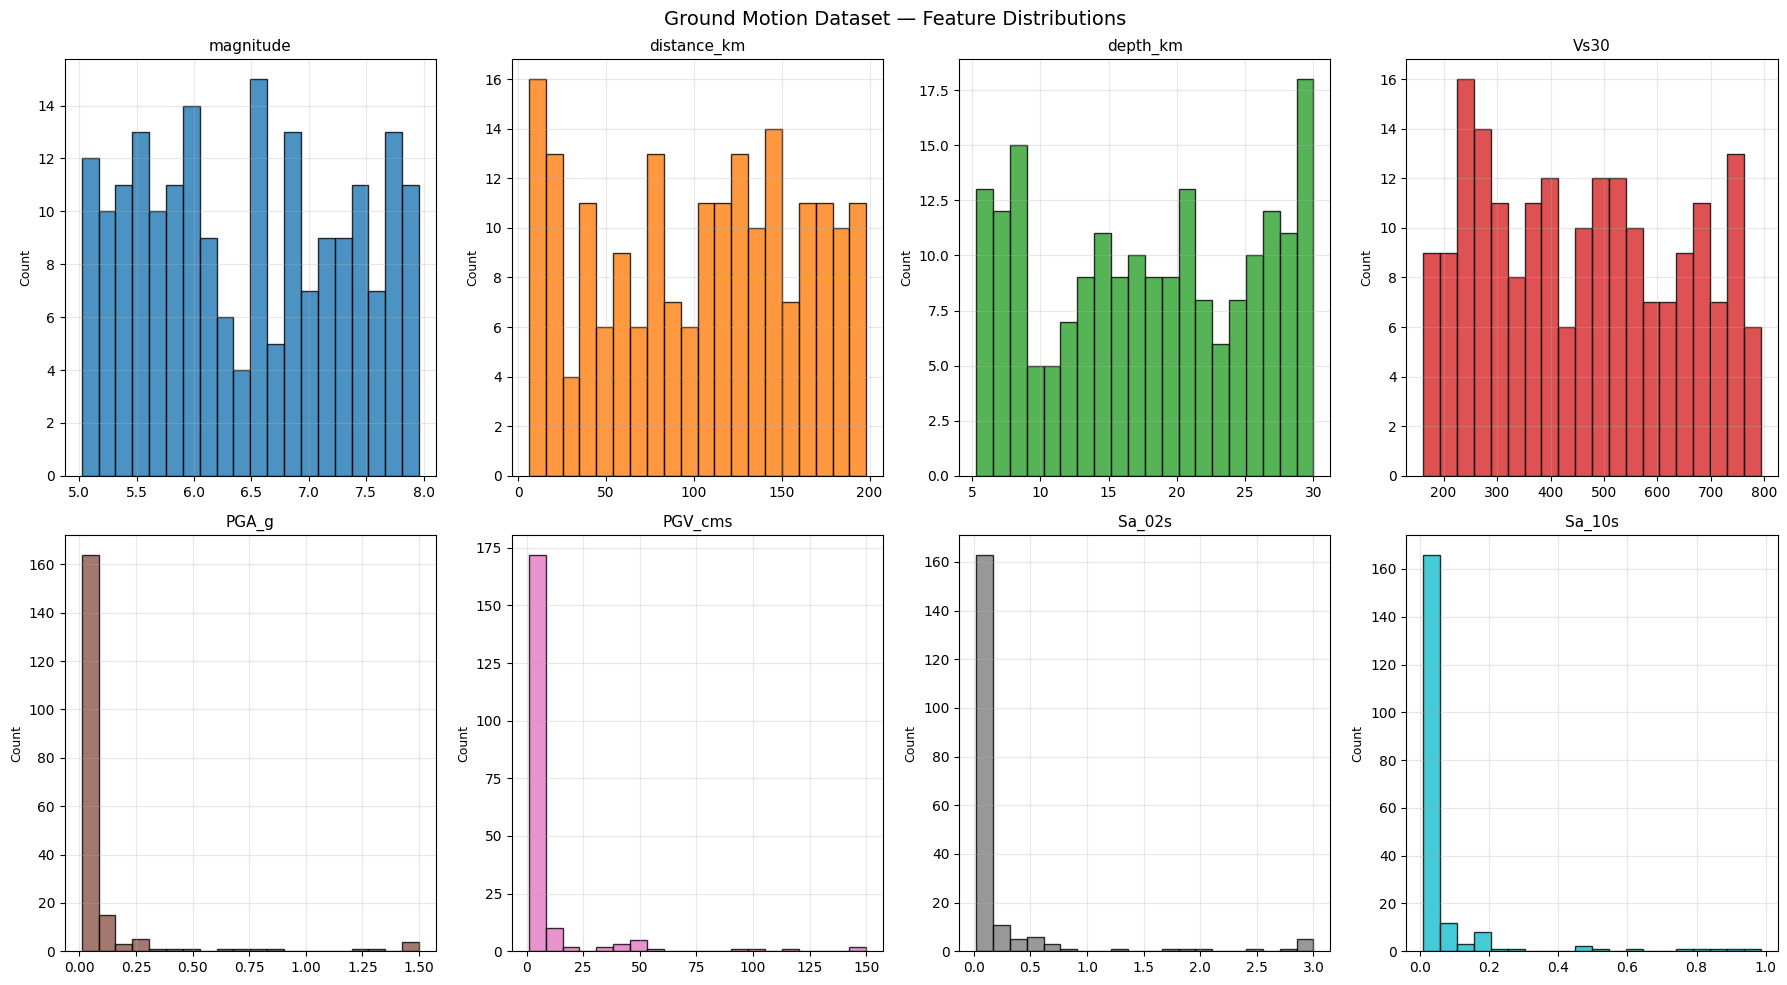

Site class counts:
site_class
A      7
B    123
C     65
D      5
Name: count, dtype: int64

Fault type counts:
fault_type
normal         71
strike-slip    65
reverse        64
Name: count, dtype: int64


In [3]:
# ───────────────────────────────────────────────────────
# EDA: DISTRIBUTIONS AND CORRELATIONS
# ───────────────────────────────────────────────────────

fig = plt.figure(figsize=(18, 10))
gs  = gridspec.GridSpec(2, 4, figure=fig)

numeric_cols = ['magnitude', 'distance_km', 'depth_km', 'Vs30',
                'PGA_g', 'PGV_cms', 'Sa_02s', 'Sa_10s']
colors = plt.cm.tab10(np.linspace(0, 0.9, len(numeric_cols)))

for i, (col, clr) in enumerate(zip(numeric_cols, colors)):
    row, col_idx = divmod(i, 4)
    ax = fig.add_subplot(gs[row, col_idx])
    ax.hist(df[col], bins=20, color=clr, edgecolor='k', alpha=0.8)
    ax.set_title(col, fontsize=11)
    ax.set_ylabel('Count', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Ground Motion Dataset — Feature Distributions', fontsize=14)
plt.tight_layout()
plt.show()

# Counts for categoricals
print("Site class counts:")
print(df['site_class'].value_counts().sort_index())
print("\nFault type counts:")
print(df['fault_type'].value_counts())

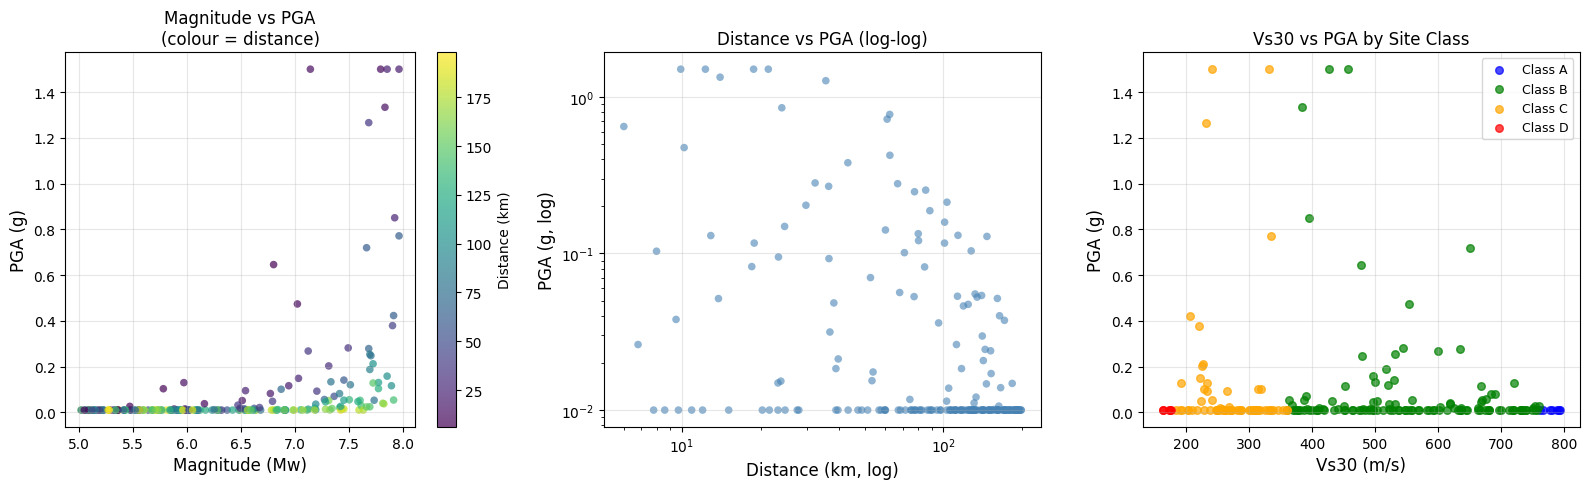

In [4]:
# ───────────────────────────────────────────────────────
# EDA: SCATTER PLOTS — Key Relationships
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Magnitude vs PGA
sc1 = axes[0].scatter(df['magnitude'], df['PGA_g'],
                       c=df['distance_km'], cmap='viridis', s=30, alpha=0.7, edgecolors='none')
plt.colorbar(sc1, ax=axes[0], label='Distance (km)')
axes[0].set_xlabel('Magnitude (Mw)', fontsize=12)
axes[0].set_ylabel('PGA (g)', fontsize=12)
axes[0].set_title('Magnitude vs PGA\n(colour = distance)', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Distance vs PGA (log-log)
axes[1].scatter(df['distance_km'], df['PGA_g'], c='steelblue', s=30, alpha=0.6, edgecolors='none')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Distance (km, log)', fontsize=12)
axes[1].set_ylabel('PGA (g, log)', fontsize=12)
axes[1].set_title('Distance vs PGA (log-log)', fontsize=12)
axes[1].grid(True, alpha=0.3)

# Vs30 vs PGA by site class
sc_colors = {'A': 'blue', 'B': 'green', 'C': 'orange', 'D': 'red', 'E': 'purple'}
for sc, grp in df.groupby('site_class'):
    axes[2].scatter(grp['Vs30'], grp['PGA_g'], label=f'Class {sc}',
                    color=sc_colors[sc], s=30, alpha=0.7)
axes[2].set_xlabel('Vs30 (m/s)', fontsize=12)
axes[2].set_ylabel('PGA (g)', fontsize=12)
axes[2].set_title('Vs30 vs PGA by Site Class', fontsize=12)
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Part 2: Log-Transform Targets + Feature Engineering

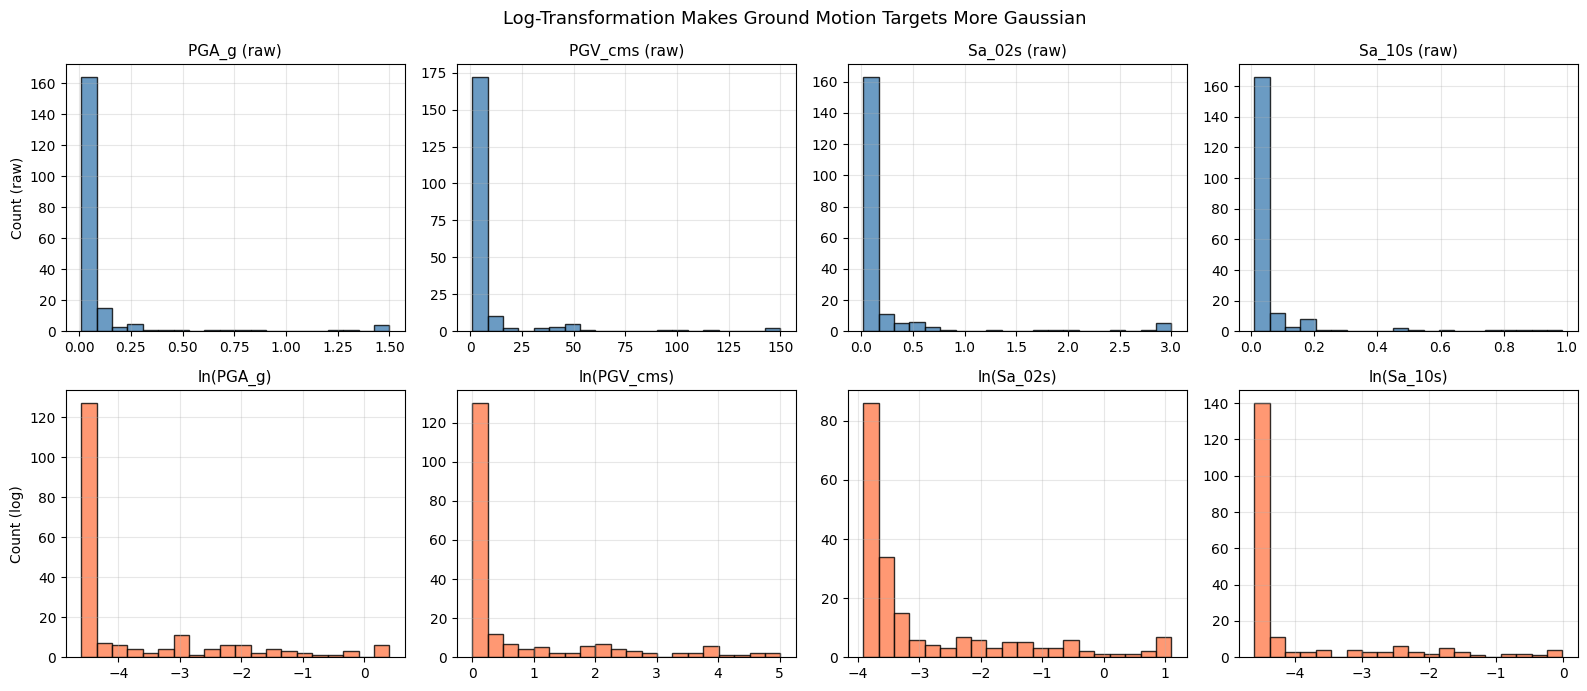

In [5]:
# ───────────────────────────────────────────────────────
# LOG-TRANSFORM TARGETS (lognormal distribution of GM)
# ───────────────────────────────────────────────────────

target_cols = ['PGA_g', 'PGV_cms', 'Sa_02s', 'Sa_10s']

# Show that log-transformed targets are more Gaussian
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, col in enumerate(target_cols):
    # Raw
    axes[0, i].hist(df[col], bins=20, color='steelblue', edgecolor='k', alpha=0.8)
    axes[0, i].set_title(f'{col} (raw)', fontsize=11)
    axes[0, i].grid(True, alpha=0.3)
    # Log-transformed
    axes[1, i].hist(np.log(df[col]), bins=20, color='coral', edgecolor='k', alpha=0.8)
    axes[1, i].set_title(f'ln({col})', fontsize=11)
    axes[1, i].grid(True, alpha=0.3)

axes[0, 0].set_ylabel('Count (raw)', fontsize=10)
axes[1, 0].set_ylabel('Count (log)', fontsize=10)
plt.suptitle('Log-Transformation Makes Ground Motion Targets More Gaussian', fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# ───────────────────────────────────────────────────────
# FEATURE ENGINEERING
# ───────────────────────────────────────────────────────

df_eng = df.copy()

# 1. Encode site_class ordinal (A=5 stiffest, E=1 softest)
site_ord = {'A': 5, 'B': 4, 'C': 3, 'D': 2, 'E': 1}
df_eng['site_class_ord'] = df_eng['site_class'].map(site_ord)

# 2. Encode fault_type ordinal (reverse produces highest GM)
fault_ord = {'reverse': 2, 'strike-slip': 1, 'normal': 0}
df_eng['fault_type_ord'] = df_eng['fault_type'].map(fault_ord)

# 3. Engineering features
df_eng['log_distance'] = np.log(df_eng['distance_km'])    # log-linear attenuation
df_eng['log_Vs30']     = np.log(df_eng['Vs30'])           # log-linear site effect

# 4. Log-transform targets
for col in target_cols:
    df_eng[f'log_{col}'] = np.log(df_eng[col])

# Define feature and target columns
feature_cols = ['magnitude', 'log_distance', 'depth_km',
                'log_Vs30', 'site_class_ord', 'fault_type_ord']
log_target_cols = [f'log_{c}' for c in target_cols]

X_all = df_eng[feature_cols].values.astype(np.float32)
y_all = df_eng[log_target_cols].values.astype(np.float32)

print(f"Features ({len(feature_cols)}): {feature_cols}")
print(f"Targets  ({len(log_target_cols)}): {log_target_cols}")
print(f"\nX: {X_all.shape}  y: {y_all.shape}")

Features (6): ['magnitude', 'log_distance', 'depth_km', 'log_Vs30', 'site_class_ord', 'fault_type_ord']
Targets  (4): ['log_PGA_g', 'log_PGV_cms', 'log_Sa_02s', 'log_Sa_10s']

X: (200, 6)  y: (200, 4)


In [7]:
# ───────────────────────────────────────────────────────
# TRAIN / TEST SPLIT AND SCALING
# ───────────────────────────────────────────────────────

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
X_train_sc = scaler_X.fit_transform(X_train)
X_test_sc  = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_sc = scaler_y.fit_transform(y_train)
y_test_sc  = scaler_y.transform(y_test)

# PyTorch tensors
X_tr = torch.tensor(X_train_sc, dtype=torch.float32)
y_tr = torch.tensor(y_train_sc, dtype=torch.float32)
X_te = torch.tensor(X_test_sc,  dtype=torch.float32)
y_te = torch.tensor(y_test_sc,  dtype=torch.float32)

# LSTM expects (batch, seq_len, features) — treat each sample as seq_len=1
X_tr_lstm = X_tr.unsqueeze(1)  # (N, 1, 6)
X_te_lstm = X_te.unsqueeze(1)

print(f"Train: {X_tr.shape}  |  Test: {X_te.shape}")
print(f"LSTM input shape: {X_tr_lstm.shape}  (batch, seq_len=1, features=6)")

Train: torch.Size([160, 6])  |  Test: torch.Size([40, 6])
LSTM input shape: torch.Size([160, 1, 6])  (batch, seq_len=1, features=6)


---

## Part 3: LSTM-Based Ground Motion Model

In [8]:
# ───────────────────────────────────────────────────────
# LSTM MODEL DEFINITION
# ───────────────────────────────────────────────────────

class GroundMotionLSTM(nn.Module):
    """
    LSTM-based ground motion predictor.

    Input:  (batch, seq_len=1, n_features=6)
    Output: (batch, 4)  — log(PGA, PGV, Sa02, Sa10)

    The LSTM extracts feature interactions, and a linear head
    maps the hidden state to multi-output predictions.
    """
    def __init__(self, in_features=6, hidden_size=64, n_layers=2, n_outputs=4,
                 dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=in_features,
            hidden_size=hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, n_outputs),
        )

    def forward(self, x):
        # x: (batch, seq_len, in_features)
        out, (h_n, c_n) = self.lstm(x)
        # Take last time step output
        last = out[:, -1, :]    # (batch, hidden_size)
        return self.head(last)  # (batch, n_outputs)


lstm_model = GroundMotionLSTM(in_features=6, hidden_size=64, n_layers=2, n_outputs=4)
n_params_lstm = sum(p.numel() for p in lstm_model.parameters())
print(lstm_model)
print(f"\nTotal LSTM parameters: {n_params_lstm:,}")

GroundMotionLSTM(
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=4, bias=True)
  )
)

Total LSTM parameters: 56,132


In [9]:
# ───────────────────────────────────────────────────────
# TRAIN LSTM
# ───────────────────────────────────────────────────────

def train_model(model, X_input, y_input, X_val, y_val,
                n_epochs=300, lr=1e-3, batch_size=32):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    criterion = nn.MSELoss()
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    train_hist, val_hist = [], []

    for epoch in range(n_epochs):
        model.train()
        perm = torch.randperm(X_input.shape[0])
        ep_loss = 0.0
        n_b = 0
        for i in range(0, X_input.shape[0], batch_size):
            idx = perm[i:i + batch_size]
            pred = model(X_input[idx])
            loss = criterion(pred, y_input[idx])
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            ep_loss += loss.item()
            n_b += 1
        train_hist.append(ep_loss / n_b)

        model.eval()
        with torch.no_grad():
            v_loss = criterion(model(X_val), y_val).item()
        val_hist.append(v_loss)
        scheduler.step()

        if epoch % 60 == 0 or epoch == n_epochs - 1:
            print(f"  Epoch {epoch:3d}/{n_epochs} | Train={train_hist[-1]:.4f} | Val={val_hist[-1]:.4f}")

    return train_hist, val_hist


print("Training LSTM...")
lstm_train_hist, lstm_val_hist = train_model(
    lstm_model, X_tr_lstm, y_tr, X_te_lstm, y_te, n_epochs=300
)
print("LSTM training complete.")

Training LSTM...


  Epoch   0/300 | Train=1.0059 | Val=0.9850


  Epoch  60/300 | Train=0.1105 | Val=0.2063


  Epoch 120/300 | Train=0.1033 | Val=0.2480


  Epoch 180/300 | Train=0.0930 | Val=0.2325


  Epoch 240/300 | Train=0.0917 | Val=0.2316


  Epoch 299/300 | Train=0.0966 | Val=0.2264
LSTM training complete.


---

## Part 4: Feedforward NN Baseline

In [10]:
# ───────────────────────────────────────────────────────
# FEEDFORWARD NN BASELINE
# ───────────────────────────────────────────────────────

class GroundMotionFFN(nn.Module):
    """Vanilla MLP — same capacity as LSTM for fair comparison."""
    def __init__(self, in_features=6, hidden=64, n_outputs=4, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden),       nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, n_outputs),
        )
    def forward(self, x):
        return self.net(x)


ffn_model = GroundMotionFFN(in_features=6, hidden=64, n_outputs=4)
n_params_ffn = sum(p.numel() for p in ffn_model.parameters())
print(f"FFN parameters: {n_params_ffn:,}")

print("\nTraining FFN...")
ffn_train_hist, ffn_val_hist = train_model(
    ffn_model, X_tr, y_tr, X_te, y_te, n_epochs=300
)
print("FFN training complete.")

FFN parameters: 4,868

Training FFN...
  Epoch   0/300 | Train=1.0076 | Val=0.9709


  Epoch  60/300 | Train=0.1355 | Val=0.2446


  Epoch 120/300 | Train=0.0963 | Val=0.2388


  Epoch 180/300 | Train=0.0948 | Val=0.2276


  Epoch 240/300 | Train=0.1082 | Val=0.2297


  Epoch 299/300 | Train=0.0819 | Val=0.2293
FFN training complete.


---

## Part 5: Evaluate — R² and RMSE per Output

In [11]:
# ───────────────────────────────────────────────────────
# EVALUATION HELPER
# ───────────────────────────────────────────────────────

def evaluate_model(model, X_input, y_true_sc, is_lstm=False):
    """
    Predict, inverse-scale, compute R² and RMSE per output.
    Returns: pred_orig (N, 4), r2_list, rmse_list
    """
    model.eval()
    with torch.no_grad():
        pred_sc = model(X_input).numpy()

    # Inverse scale both pred and true from log-space
    pred_log = scaler_y.inverse_transform(pred_sc)    # back to log(GM)
    true_log = scaler_y.inverse_transform(y_true_sc.numpy())

    pred_orig = np.exp(pred_log)  # back to original scale
    true_orig = np.exp(true_log)

    r2_list, rmse_list = [], []
    for j in range(pred_orig.shape[1]):
        r2   = r2_score(true_orig[:, j], pred_orig[:, j])
        rmse = np.sqrt(mean_squared_error(true_orig[:, j], pred_orig[:, j]))
        r2_list.append(r2)
        rmse_list.append(rmse)

    return pred_orig, true_orig, r2_list, rmse_list


pred_lstm, true_orig, r2_lstm, rmse_lstm = evaluate_model(
    lstm_model, X_te_lstm, y_te, is_lstm=True
)
pred_ffn, _, r2_ffn, rmse_ffn = evaluate_model(
    ffn_model, X_te, y_te, is_lstm=False
)

print(f"{'Output':<12} {'LSTM R²':>10} {'FFN R²':>10} {'LSTM RMSE':>12} {'FFN RMSE':>10}")
print("─" * 58)
units = ['g', 'cm/s', 'g', 'g']
for j, (col, unit) in enumerate(zip(target_cols, units)):
    print(f"  {col:<10} {r2_lstm[j]:>10.4f} {r2_ffn[j]:>10.4f} "
          f"{rmse_lstm[j]:>10.4f}{unit:>3} {rmse_ffn[j]:>8.4f}{unit}")

Output          LSTM R²     FFN R²    LSTM RMSE   FFN RMSE
──────────────────────────────────────────────────────────
  PGA_g          0.8720     0.8314     0.0465  g   0.0533g
  PGV_cms        0.4258     0.3687    19.3291cm/s  20.2676cm/s
  Sa_02s         0.9222     0.8458     0.0924  g   0.1300g
  Sa_10s         0.6911     0.6529     0.0482  g   0.0511g


---

## Part 6: Actual vs Predicted Scatter for PGA

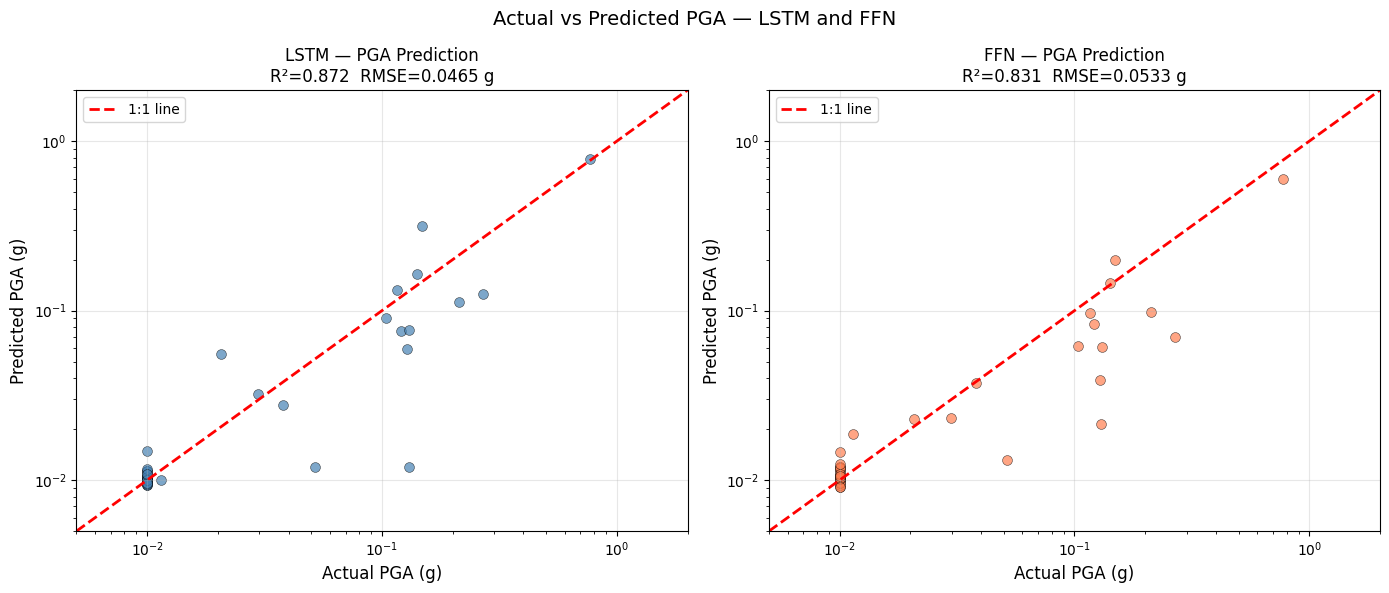

In [12]:
# ───────────────────────────────────────────────────────
# PGA SCATTER: ACTUAL vs PREDICTED
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lim = (0.005, 2.0)

for ax, (pred, label) in zip(axes, [(pred_lstm, 'LSTM'), (pred_ffn, 'FFN')]):
    r2_pga   = r2_lstm[0] if label == 'LSTM' else r2_ffn[0]
    rmse_pga = rmse_lstm[0] if label == 'LSTM' else rmse_ffn[0]

    ax.scatter(true_orig[:, 0], pred[:, 0], alpha=0.7, edgecolors='k',
               linewidth=0.4, s=50, color='steelblue' if label == 'LSTM' else 'coral')
    ax.plot(lim, lim, 'r--', linewidth=2, label='1:1 line')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(*lim)
    ax.set_ylim(*lim)
    ax.set_xlabel('Actual PGA (g)', fontsize=12)
    ax.set_ylabel('Predicted PGA (g)', fontsize=12)
    ax.set_title(f'{label} — PGA Prediction\nR²={r2_pga:.3f}  RMSE={rmse_pga:.4f} g',
                 fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle('Actual vs Predicted PGA — LSTM and FFN', fontsize=14)
plt.tight_layout()
plt.show()

---

## Part 7: XGBoost (GradientBoosting) Comparison

In [13]:
# ───────────────────────────────────────────────────────
# XGBOOST COMPARISON (via sklearn GradientBoosting)
# ───────────────────────────────────────────────────────

xgb_base = GradientBoostingRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, random_state=42
)
xgb_model = MultiOutputRegressor(xgb_base, n_jobs=-1)

# Train on log-scale targets (same as DL models)
xgb_model.fit(X_train, y_train)  # raw numpy, not scaled

xgb_pred_log = xgb_model.predict(X_test)     # in log-scale
xgb_pred_orig = np.exp(xgb_pred_log)

true_log_orig = np.exp(y_test)                # back from log-space

r2_xgb, rmse_xgb = [], []
for j in range(4):
    r2_xgb.append(r2_score(true_log_orig[:, j],    xgb_pred_orig[:, j]))
    rmse_xgb.append(np.sqrt(mean_squared_error(true_log_orig[:, j], xgb_pred_orig[:, j])))

print(f"\n{'Output':<12} {'LSTM R²':>10} {'FFN R²':>10} {'XGB R²':>10}")
print("─" * 45)
for j, col in enumerate(target_cols):
    print(f"  {col:<10} {r2_lstm[j]:>10.4f} {r2_ffn[j]:>10.4f} {r2_xgb[j]:>10.4f}")


Output          LSTM R²     FFN R²     XGB R²
─────────────────────────────────────────────
  PGA_g          0.8720     0.8314     0.7956
  PGV_cms        0.4258     0.3687     0.4161
  Sa_02s         0.9222     0.8458     0.7951
  Sa_10s         0.6911     0.6529     0.6527


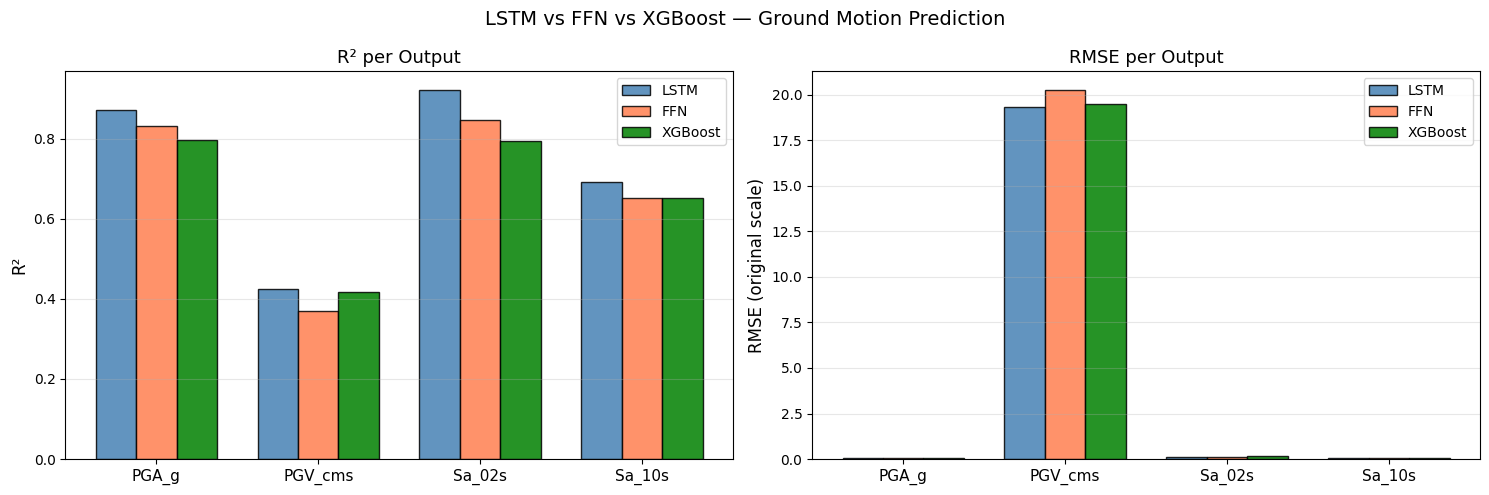

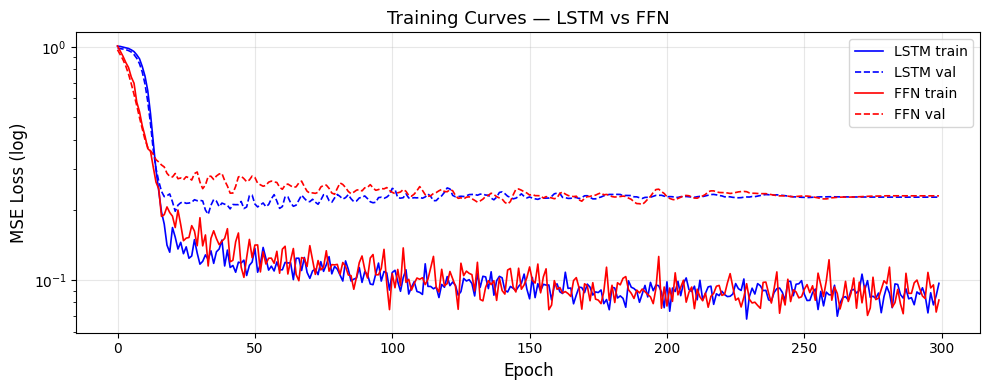

In [14]:
# ───────────────────────────────────────────────────────
# THREE-WAY COMPARISON PLOT
# ───────────────────────────────────────────────────────

models_r2   = {'LSTM': r2_lstm,  'FFN': r2_ffn,  'XGBoost': r2_xgb}
models_rmse = {'LSTM': rmse_lstm,'FFN': rmse_ffn,'XGBoost': rmse_xgb}
bar_colors  = ['steelblue', 'coral', 'green']
x = np.arange(len(target_cols))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for i, (name, color) in enumerate(zip(models_r2, bar_colors)):
    axes[0].bar(x + i * width, models_r2[name], width, label=name,
                color=color, edgecolor='k', alpha=0.85)
    axes[1].bar(x + i * width, models_rmse[name], width, label=name,
                color=color, edgecolor='k', alpha=0.85)

for ax, title, ylabel in zip(axes,
                              ['R² per Output', 'RMSE per Output'],
                              ['R²', 'RMSE (original scale)']):
    ax.set_xticks(x + width)
    ax.set_xticklabels(target_cols, fontsize=11)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=10)
    ax.grid(True, axis='y', alpha=0.3)

plt.suptitle('LSTM vs FFN vs XGBoost — Ground Motion Prediction', fontsize=14)
plt.tight_layout()
plt.show()

# Loss curves
fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(lstm_train_hist, 'b-', label='LSTM train', linewidth=1.2)
ax.semilogy(lstm_val_hist,   'b--',label='LSTM val',   linewidth=1.2)
ax.semilogy(ffn_train_hist,  'r-', label='FFN train',  linewidth=1.2)
ax.semilogy(ffn_val_hist,    'r--',label='FFN val',    linewidth=1.2)
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('MSE Loss (log)', fontsize=12)
ax.set_title('Training Curves — LSTM vs FFN', fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---

## Phase 4 Summary: 25 Days of Deep Learning

In [15]:
# ───────────────────────────────────────────────────────
# PHASE 4 SUMMARY TABLE
# ───────────────────────────────────────────────────────

phase4_summary = [
    ('Day 061', 'Intro to PyTorch',             'Tensors, autograd, basic operations'),
    ('Day 062', 'Linear Regression in PyTorch', 'Settlement prediction, MSELoss, gradient descent'),
    ('Day 063', 'Logistic Regression (DL)',      'Liquefaction classification'),
    ('Day 064', 'Multi-layer Perceptron',        'Pile capacity, hidden layers, ReLU'),
    ('Day 065', 'Backpropagation',               'Chain rule, gradient flow, vanishing gradient'),
    ('Day 066', 'Optimizers (SGD, Adam, RMSProp)','Bearing capacity, optimizer comparison'),
    ('Day 067', 'Regularization (Dropout, L2)',  'CPT classification, overfitting prevention'),
    ('Day 068', 'Batch Normalization',           'Settlement prediction, BN vs no-BN'),
    ('Day 069', 'Learning Rate Scheduling',      'Vs prediction, warmup + cosine annealing'),
    ('Day 070', 'CNNs for Soil Images',          'Conv2d for soil grain images'),
    ('Day 071', 'Transfer Learning',             'ResNet features for geotechnical classification'),
    ('Day 072', 'Data Augmentation (images)',    'Rotation, flip, color jitter'),
    ('Day 073', 'Recurrent Neural Networks',     'LSTM for time-series settlement data'),
    ('Day 074', 'Seq2Seq Models',                'Forecast future settlements'),
    ('Day 075', 'Attention Mechanism',           'Self-attention on pore pressure time series'),
    ('Day 076', 'Transformer Basics',            'Encoder-only for tabular geo data'),
    ('Day 077', 'Autoencoders',                  'Anomaly detection in inclinometer data'),
    ('Day 078', 'Variational Autoencoders',      'Generate synthetic CPT profiles'),
    ('Day 079', 'Physics-Informed NN (PINN)',    'Terzaghi consolidation PDE'),
    ('Day 080', 'GAN for Geotechnical Data',     'Generate realistic SPT borehole logs'),
    ('Day 081', 'TabNet',                        'Pile capacity, attention on tabular data'),
    ('Day 082', 'Hyperparameter Tuning',         'LR finder, grid search, depth comparison'),
    ('Day 083', 'Model Deployment',              'TorchScript, ONNX, Flask API, config.json'),
    ('Day 084', 'Seismic Classification (CNN)',  '1D CNN for earthquake/blast/noise'),
    ('Day 085', 'Ground Motion LSTM (Capstone)', 'Multi-output GMPE with LSTM vs FFN vs XGB'),
]

print(f"{'Day':<10} {'Topic':<38} {'Key Concept'}")
print("═" * 90)
for day, topic, concept in phase4_summary:
    print(f"{day:<10} {topic:<38} {concept}")

print("\n" + "═" * 90)
print(f"Phase 4 complete: {len(phase4_summary)} days, covering the full DL toolkit")
print("from PyTorch fundamentals through production deployment and domain applications.")

Day        Topic                                  Key Concept
══════════════════════════════════════════════════════════════════════════════════════════
Day 061    Intro to PyTorch                       Tensors, autograd, basic operations
Day 062    Linear Regression in PyTorch           Settlement prediction, MSELoss, gradient descent
Day 063    Logistic Regression (DL)               Liquefaction classification
Day 064    Multi-layer Perceptron                 Pile capacity, hidden layers, ReLU
Day 065    Backpropagation                        Chain rule, gradient flow, vanishing gradient
Day 066    Optimizers (SGD, Adam, RMSProp)        Bearing capacity, optimizer comparison
Day 067    Regularization (Dropout, L2)           CPT classification, overfitting prevention
Day 068    Batch Normalization                    Settlement prediction, BN vs no-BN
Day 069    Learning Rate Scheduling               Vs prediction, warmup + cosine annealing
Day 070    CNNs for Soil Images              

---

## Practice Exercises

### Exercise 1: Bidirectional LSTM
Replace `nn.LSTM(bidirectional=False)` with `bidirectional=True`. Double the hidden_size of the head. Does it improve Sa prediction?

### Exercise 2: Residual Sigma
Ground motion models also report **σ (sigma)** — the standard deviation of log residuals. Compute σ for each output and compare LSTM, FFN, and XGBoost.

### Exercise 3: Probabilistic Prediction
Add a second head to LSTM that predicts σ (uncertainty). Use a Gaussian NLL loss: `-log N(y; μ, σ²)`.

In [16]:
# EXERCISE SPACE

# Exercise 1: Bidirectional LSTM
# lstm_bidir = nn.LSTM(input_size=6, hidden_size=64, num_layers=2,
#                      batch_first=True, bidirectional=True)
# head_bidir = nn.Linear(128, 4)  # 128 = 2 * hidden_size

# Exercise 2: Residual sigma
# log_residuals = np.log(true_log_orig) - np.log(pred_lstm + 1e-9)
# sigma = log_residuals.std(axis=0)
# for j, col in enumerate(target_cols):
#     print(f"  {col}: sigma(LSTM)={sigma[j]:.3f}")

# Exercise 3: Gaussian NLL loss
# class ProbGMPE(nn.Module):
#     def __init__(self, in_features=6, hidden=64, n_outputs=4):
#         super().__init__()
#         self.lstm = nn.LSTM(in_features, hidden, 2, batch_first=True)
#         self.mu_head    = nn.Linear(hidden, n_outputs)
#         self.sigma_head = nn.Linear(hidden, n_outputs)
#     def forward(self, x):
#         out, _ = self.lstm(x)
#         h = out[:, -1, :]
#         mu    = self.mu_head(h)
#         sigma = F.softplus(self.sigma_head(h)) + 1e-4
#         return mu, sigma
# criterion = lambda mu, sigma, y: (torch.log(sigma) + 0.5 * ((y - mu) / sigma)**2).mean()

---

## Key Takeaways

1. **Log-transforming ground motion targets is essential.** PGA spans three orders of magnitude — MSELoss on raw values would be dominated by large-amplitude events.

2. **LSTMs can work on tabular data (seq_len=1).** The LSTM's gating mechanism learns feature interactions that a plain MLP misses, especially for correlated inputs like magnitude and distance.

3. **Multi-output regression is straightforward in PyTorch.** Replace the single output node with n_outputs and MSELoss aggregates over all targets automatically.

4. **XGBoost is a competitive baseline.** With 200 samples, gradient boosting often matches or beats DL — use XGBoost as the bar your neural net must clear.

5. **Physically consistent synthetic data enables rigorous development.** By encoding Atkinson-Boore-like attenuation into the data generator, our models learn meaningful GMPE-style relationships.

---

## How This Connects to ML

| Concept | Role in GMPE | Traditional Equivalent |
|---|---|---|
| Log-transform + MSELoss | Fit in log-space | OLS on ln(IM) — standard in seismology |
| LSTM gating | Feature interaction learning | Interaction terms in regression |
| StandardScaler on features | Normalize before LSTM | z-score normalization |
| Multi-output head | PGA + PGV + Sa simultaneously | Separate regression for each IM |
| Gradient clipping | Stable LSTM training | Ridge constraint on OLS |
| R² + RMSE per IM | Per-target performance | Standard GMPE evaluation metrics |

---

## Phase 5 Preview — Geotechnical AI Applications

| Day | Topic |
|-----|-------|
| 086 | Site Response Analysis with ML |
| 087 | Slope Stability Prediction |
| 088 | Pile Driving Formula (ML-based) |
| 089 | Foundation Settlement Monitoring (IoT + ML) |
| 090 | Landslide Susceptibility Mapping (GIS + ML) |

Phase 5 integrates everything learned so far into real-world geotechnical workflows.

---

*Day 085 of 100 — Phase 4 Complete! Deep learning is now in your geotechnical toolkit!*